# OpenCode with the AWS CLI against IaCGen-MAS, OpenCode with the Validator and zero-shot on Terraform

## Setup

In [1]:
import sys, os, re, json, csv, glob, warnings, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
csv.field_size_limit(sys.maxsize)

FINAL = Path("../results"); DATA = Path("../data"); RES = Path("result/final")
RUNS = Path(os.environ.get("IACGOD_RUNS", "../runs"))
CACHE = FINAL / "_analysis_cache"; CACHE.mkdir(exist_ok=True)
FIG = Path("plots/opencode_agent_tf"); FIG.mkdir(parents=True, exist_ok=True)
OUT = RES
plt.style.use("ggplot"); sns.set_palette("muted")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_colwidth", 90)

AGENT = "TF_RealAWS_OpencodeAgent_DSV4F"
SYSTEMS = {
    "IaCGen-MAS": "TF_RealAWS_DSV4F",
    "OpenCode + Validator": "TF_RealAWS_OpenCode_DSV4F",
    "OpenCode (AWS CLI)": AGENT,
    "Zero-shot": "TF_RealAWS_OneShot_DSV4F",
}
ORDER = list(SYSTEMS)
PALETTE = dict(zip(ORDER, sns.color_palette("muted", len(ORDER))))
PRICE = (0.0121, 1.28)

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (c - h, c + h)

def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj

def mcnemar_exact(a, b):
    only_a = int((a & ~b).sum()); only_b = int((~a & b).sum())
    n = only_a + only_b
    p = 1.0 if n == 0 else stats.binomtest(min(only_a, only_b), n, 0.5).pvalue
    return dict(both=int((a & b).sum()), only_first=only_a, only_second=only_b, neither=int((~a & ~b).sum()), p=p)

## Load the results

In [2]:
bench = pd.read_csv(DATA / "tf_eval_benchmark_real_aws.csv").drop_duplicates("row_number").set_index("row_number")

frames = []
for name, e in SYSTEMS.items():
    r = pd.read_csv(FINAL / e / "results_final.csv", engine="python")
    r["row_index"] = np.arange(len(r))
    r["system"] = name; r["exp"] = e
    r["difficulty"] = r.row_number.map(bench["difficulty"])
    r["passed"] = r.final_validation_passed.astype(str).str.lower().eq("true")
    if name == "OpenCode + Validator":
        r["passed"] = r.passed & (r.iterations_used <= 15)
    frames.append(r)
runs = pd.concat(frames, ignore_index=True)
runs["system"] = pd.Categorical(runs.system, ORDER, ordered=True)
agent = runs[runs.system == "OpenCode (AWS CLI)"].copy()
runs.groupby("system", observed=True).agg(rows=("row_number", "size"), passed=("passed", "sum"), invalid=("validity", lambda s: int(s.astype(str).str.startswith("invalid").sum())))

,rows,passed,invalid
system,,,
IaCGen-MAS,250,246,0
OpenCode + Validator,250,242,4
OpenCode (AWS CLI),250,223,1
Zero-shot,250,111,4


## Pass rate

In [3]:
rows = []
for name, g in runs.groupby("system", observed=True, sort=False):
    lo, hi = wilson(int(g.passed.sum()), len(g))
    valid = g[~g.validity.astype(str).str.startswith("invalid")]
    rows.append(dict(system=name, rows=len(g), passed=int(g.passed.sum()), pass_rate=g.passed.mean(), ci_lo=lo, ci_hi=hi,
                     valid_rows=len(valid), pass_rate_valid=valid.passed.mean()))
HEAD = pd.DataFrame(rows)
HEAD.round(4)

,system,rows,passed,pass_rate,ci_lo,ci_hi,valid_rows,pass_rate_valid
0,IaCGen-MAS,250,246,0.984,0.9596,0.9938,250,0.9840
1,OpenCode + Validator,250,242,0.968,0.9381,0.9837,246,0.9837
2,OpenCode (AWS CLI),250,223,0.892,0.8474,0.9247,249,0.8956
3,Zero-shot,250,111,0.444,0.3837,0.5060,246,0.4512


## Pass rate by difficulty level

difficulty,1,2,3,4,5
system,,,,,
IaCGen-MAS,100.0,100.0,100.0,98.0,94.0
OpenCode + Validator,100.0,98.0,98.0,96.0,92.0
OpenCode (AWS CLI),100.0,88.0,90.0,88.0,80.0
Zero-shot,56.0,46.0,48.0,42.0,30.0


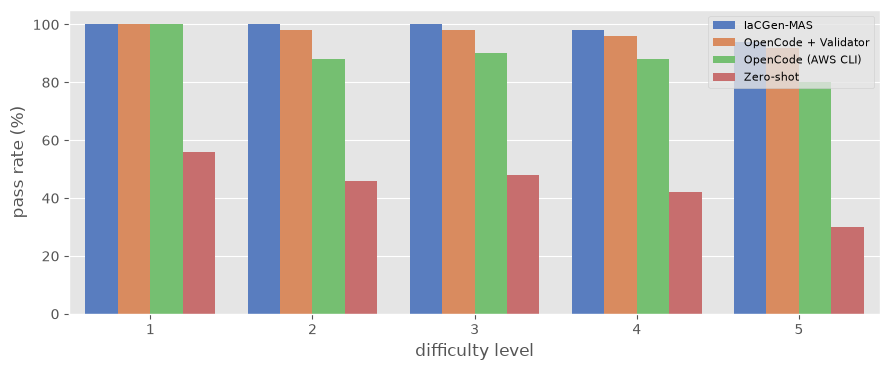

In [4]:
LEVEL = runs.pivot_table(index="system", columns="difficulty", values="passed", aggfunc="mean", observed=True).mul(100).round(1)
display(LEVEL)
fig, ax = plt.subplots(figsize=(9, 3.8))
d = runs.groupby(["difficulty", "system"], observed=True).passed.mean().mul(100).reset_index()
sns.barplot(data=d, x="difficulty", y="passed", hue="system", hue_order=ORDER, palette=PALETTE, ax=ax)
ax.set_xlabel("difficulty level"); ax.set_ylabel("pass rate (%)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "pass_by_level.png", dpi=160); plt.show()

## Paired comparisons with the coding agent

In [5]:
ag = agent.set_index("row_number")
pairs = []
for name in ORDER:
    if name == "OpenCode (AWS CLI)":
        continue
    o = runs[runs.system == name].set_index("row_number")
    idx = ag.index.intersection(o.index)
    m = mcnemar_exact(ag.loc[idx].passed.values, o.loc[idx, "passed"].astype(bool).values)
    pairs.append(dict(other=name, rows=len(idx), agent_pass=int(ag.loc[idx].passed.sum()), other_pass=int(o.loc[idx, "passed"].sum()),
                      both=m["both"], only_agent=m["only_first"], only_other=m["only_second"], neither=m["neither"], p=m["p"]))
PAIRS = pd.DataFrame(pairs)
PAIRS["p_holm"] = holm(PAIRS.p.values)
PAIRS.round(4)

,other,rows,agent_pass,other_pass,both,only_agent,only_other,neither,p,p_holm
0,IaCGen-MAS,250,223,246,223,0,23,4,0.0000,0.0000
1,OpenCode + Validator,250,223,242,218,5,24,3,0.0005,0.0005
2,Zero-shot,250,223,111,104,119,7,20,0.0000,0.0000


## Effort and cost

In [6]:
def eff(g):
    c = g.token_input_tokens.fillna(0) / 1e6 * PRICE[0] + g.token_output_tokens.fillna(0) / 1e6 * PRICE[1]
    return pd.Series(dict(rows=len(g), llm_calls_mean=g.llm_calls_total.mean(), llm_calls_median=g.llm_calls_total.median(),
                          tokens_k_mean=g.token_all_tokens.mean() / 1e3, input_k_mean=g.token_input_tokens.mean() / 1e3,
                          output_k_mean=g.token_output_tokens.mean() / 1e3, minutes_mean=g.duration_seconds.mean() / 60,
                          minutes_median=g.duration_seconds.median() / 60, usd_per_scenario=c.mean(),
                          shell_calls_mean=g.agent_shell_calls.mean(), aws_calls_mean=g.agent_aws_calls.mean(),
                          deploy_attempts_mean=g.agent_deploy_attempts.mean(), deploy_attempts_median=g.agent_deploy_attempts.median()))
AGENT_EFFORT = pd.concat({"all": eff(agent), "passed": eff(agent[agent.passed]), "failed": eff(agent[~agent.passed])}, axis=1).T.round(3)
display(AGENT_EFFORT)
J = pd.read_csv(FINAL / "repair_loop_tables" / "J_llm_cost.csv")
J = J[J.run.isin(SYSTEMS.values())][["run", "approach", "pass_pct", "llm_calls_mean", "prompt_ktok_mean", "completion_ktok_mean", "usd_per_scenario", "usd_per_pass"]]
a = AGENT_EFFORT.loc["all"]
J = pd.concat([J, pd.DataFrame([dict(run=AGENT, approach="OpenCode (AWS CLI)", pass_pct=100 * agent.passed.mean(), llm_calls_mean=a.llm_calls_mean,
                                     prompt_ktok_mean=a.input_k_mean, completion_ktok_mean=a.output_k_mean, usd_per_scenario=a.usd_per_scenario,
                                     usd_per_pass=a.usd_per_scenario * len(agent) / agent.passed.sum())])], ignore_index=True)
other = runs[runs.system.isin(["IaCGen-MAS", "OpenCode + Validator"])].groupby("system", observed=True).agg(minutes_mean=("duration_seconds", lambda s: s.mean() / 60), tokens_k_mean=("token_all_tokens", lambda s: s.mean() / 1e3))
display(other.round(2))
COST = J.round(4)
COST

,rows,llm_calls_mean,llm_calls_median,tokens_k_mean,input_k_mean,output_k_mean,minutes_mean,minutes_median,usd_per_scenario,shell_calls_mean,aws_calls_mean,deploy_attempts_mean,deploy_attempts_median
all,250.0,31.616,19.0,138.647,130.146,8.502,9.980,5.641,0.012,23.500,4.676,2.424,1.0
passed,223.0,29.570,17.0,130.570,122.623,7.947,9.006,5.105,0.012,21.960,4.462,2.350,1.0
failed,27.0,48.519,36.0,205.360,192.277,13.083,18.025,9.777,0.019,36.222,6.444,3.037,2.0


,minutes_mean,tokens_k_mean
system,,
IaCGen-MAS,16.73,141.28
OpenCode + Validator,7.89,24.86


,run,approach,pass_pct,llm_calls_mean,prompt_ktok_mean,completion_ktok_mean,usd_per_scenario,usd_per_pass
0,TF_RealAWS_DSV4F,IaCGen-MAS,98.4,8.000,114.500,26.800,0.0357,0.0363
1,TF_RealAWS_OneShot_DSV4F,Zero-shot,44.4,1.000,0.400,10.000,0.0128,0.0288
2,TF_RealAWS_OpenCode_DSV4F,OpenCode+Validator,96.8,11.000,20.600,15.700,0.0203,0.0210
3,TF_RealAWS_OpencodeAgent_DSV4F,OpenCode (AWS CLI),89.2,31.616,130.146,8.502,0.0120,0.0135


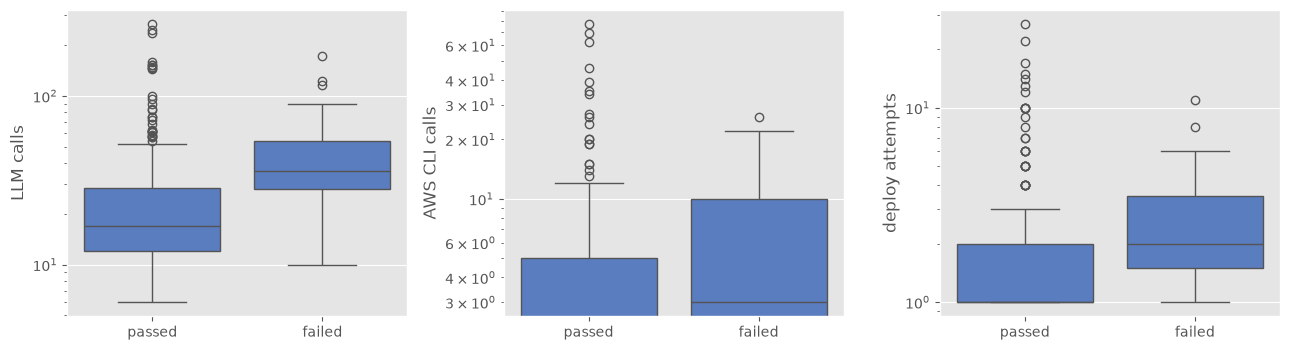

llm_calls_total          0.00001
token_all_tokens         0.00155
agent_aws_calls          0.01412
agent_deploy_attempts    0.00049
duration_seconds         0.00063
Name: mann_whitney_p, dtype: float64

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, lab in zip(axes, ["llm_calls_total", "agent_aws_calls", "agent_deploy_attempts"], ["LLM calls", "AWS CLI calls", "deploy attempts"]):
    sns.boxplot(data=agent.assign(outcome=np.where(agent.passed, "passed", "failed")), x="outcome", y=col, ax=ax, order=["passed", "failed"])
    ax.set_ylabel(lab); ax.set_xlabel(""); ax.set_yscale("log")
plt.tight_layout(); plt.savefig(FIG / "agent_effort_by_outcome.png", dpi=160); plt.show()
w = {c: stats.mannwhitneyu(agent.loc[agent.passed, c], agent.loc[~agent.passed, c]).pvalue for c in ["llm_calls_total", "token_all_tokens", "agent_aws_calls", "agent_deploy_attempts", "duration_seconds"]}
pd.Series(w, name="mann_whitney_p").round(5)

## Why the coding agent fails

In [8]:
def stage_failed(r):
    for s in ("tflint", "terraform-validate", "trivy"):
        v = r.get(f"val_stage_{s}_passed")
        if pd.notna(v) and str(v).lower() == "false":
            return s
    return None

def category(r):
    msg = f"{r.get('deploy_error_message') or ''} {r.get('invalid_reason') or ''}"
    if r.status == "workspace_escape":
        return "workspace escape"
    if r.status == "harness_timeout":
        return "session timeout"
    s = stage_failed(r)
    if s:
        return {"tflint": "syntax", "terraform-validate": "syntax", "trivy": "security"}[s]
    if "No value for required variable" in msg:
        return "variable without default"
    if "created 0 resources" in msg:
        return "no resources created"
    if re.search(r"already exists|scheduled for deletion|You can't create this secret", msg):
        return "name already in use"
    if re.search(r"No default VPC|explicit deny|not subscribed|can't create new App Runner", msg):
        return "account or service restriction"
    if "timeout while waiting" in msg:
        return "deployment wait timed out"
    return "other deployment error"

GROUP = {"variable without default": "scoring rule the agent's test skipped", "no resources created": "scoring rule the agent's test skipped",
         "syntax": "static check", "security": "static check", "workspace escape": "harness", "session timeout": "harness",
         "name already in use": "deployment environment", "account or service restriction": "deployment environment",
         "deployment wait timed out": "deployment error", "other deployment error": "deployment error"}
fails = agent[~agent.passed].copy()
fails["category"] = fails.apply(category, axis=1)
fails["group"] = fails.category.map(GROUP)
FAIL_CAT = fails.groupby(["group", "category"]).agg(rows=("row_number", "size"), row_numbers=("row_number", lambda s: ", ".join(map(str, sorted(s))))).reset_index()
FAIL_CAT

,group,category,rows,row_numbers
0,deployment environment,account or service restriction,2,"179, 363"
1,deployment environment,name already in use,3,"204, 229, 350"
2,deployment error,deployment wait timed out,2,"166, 184"
3,deployment error,other deployment error,3,"50, 84, 338"
4,harness,session timeout,1,249
5,harness,workspace escape,7,"53, 149, 172, 217, 231, 343, 344"
6,scoring rule the agent's test skipped,no resources created,1,351
7,scoring rule the agent's test skipped,variable without default,3,"85, 160, 201"
8,static check,security,4,"127, 144, 241, 369"
9,static check,syntax,1,326


In [9]:
fails.assign(error=fails.deploy_error_message.fillna("").str.replace(r"\s+", " ", regex=True).str[:150])[["row_number", "difficulty", "status", "category", "error"]].sort_values("row_number")

,row_number,difficulty,status,category,error
544,50,2,ok,other deployment error,aws_iam_role.grafana_monitoring_role: creating IAM Role (Grafana-MonitoringRole): oper...
547,53,2,workspace_escape,workspace escape,"apply: No value for required variable — The root module input variable ""repository_nam..."
566,84,3,ok,other deployment error,apply: Invalid index — ├──────────────── │ aws_kms_key.this is empty tuple The given k...
567,85,3,ok,variable without default,"apply: No value for required variable — The root module input variable ""topic_name"" is..."
593,127,3,ok,security,
604,144,4,ok,security,
609,149,4,workspace_escape,workspace escape,
617,160,4,ok,variable without default,"apply: No value for required variable — The root module input variable ""name"" is not s..."
622,166,5,ok,deployment wait timed out,aws_s3_bucket_lifecycle_configuration.core: creating S3 Bucket (benchmark-bucket-tf5x)...
627,172,5,workspace_escape,workspace escape,aws_security_group.this: creating Security Group (security-group-dev-sg): operation er...


## The agent's own tests

In [10]:
PAT = {
    "deploy_cmd": re.compile(r"terraform\s+(-chdir=\S+\s+)?apply"),
    "var_values": re.compile(r"(-var[ =]|-var-file|TF_VAR_|\.tfvars)"),
    "plan": re.compile(r"terraform\s+(-chdir=\S+\s+)?plan"),
    "tf_validate": re.compile(r"terraform\s+(-chdir=\S+\s+)?validate"),
    "tflint": re.compile(r"\btflint\b"),
    "trivy": re.compile(r"\btrivy\b"),
    "aws_cli": re.compile(r"(^|[;&|(\s])aws\s+[a-z0-9-]+\s"),
    "destroy": re.compile(r"terraform\s+(-chdir=\S+\s+)?destroy"),
    "web_request": re.compile(r"(curl|wget|urllib|requests\.get|http\.client)[^\n]*https?://"),
}
COMPLETE = re.compile(r"Apply complete! Resources: [1-9]")

def find_run(rid):
    for p in (RUNS / rid, *RUNS.glob(f"*/{rid}")):
        if (p / "harness_stream.jsonl").exists():
            return p
    return None

def session_features(rid):
    p = find_run(rid)
    rec = dict(run_id=rid, found=p is not None, bash_calls=0, saw_complete=False, **{k: 0 for k in PAT})
    if p is None:
        return rec
    for line in open(p / "harness_stream.jsonl", errors="ignore"):
        try:
            e = json.loads(line)
        except Exception:
            continue
        if e.get("type") != "tool_use" or e.get("part", {}).get("tool") != "bash":
            continue
        st = e["part"].get("state", {})
        cmd = str(st.get("input", {}).get("command", ""))
        out = str(st.get("output", "")) + str((st.get("metadata") or {}).get("output", ""))
        rec["bash_calls"] += 1
        for k, rx in PAT.items():
            if rx.search(cmd):
                rec[k] += 1
        if COMPLETE.search(out):
            rec["saw_complete"] = True
    return rec

cache = CACHE / f"agent_sessions_{AGENT}.csv"
rids = sorted(agent.run_id.dropna().astype(str))
if cache.exists() and sorted(pd.read_csv(cache).run_id.astype(str)) == rids:
    SESS = pd.read_csv(cache)
else:
    if not RUNS.exists():
        raise FileNotFoundError(f"{RUNS} is missing and no cache for {AGENT}; set IACGOD_RUNS")
    SESS = pd.DataFrame([session_features(r) for r in rids])
    SESS.to_csv(cache, index=False)
SESS["run_id"] = SESS.run_id.astype(str)
S = agent.assign(run_id=agent.run_id.astype(str)).merge(SESS, on="run_id", how="left")
S = S.merge(fails[["row_number", "category", "group"]], on="row_number", how="left")
S["outcome"] = np.where(S.passed, "passed", "failed")
used = lambda c: (c, lambda s: int((s > 0).sum()))
SELFTEST = S.groupby("outcome").agg(rows=("row_number", "size"), ran_apply=used("deploy_cmd"), saw_apply_complete=("saw_complete", "sum"),
                                    used_variable_values=used("var_values"), ran_plan=used("plan"), ran_validate=used("tf_validate"),
                                    ran_tflint=used("tflint"), ran_trivy=used("trivy"), used_aws_cli=used("aws_cli"), ran_destroy=used("destroy"),
                                    web_requests=used("web_request"))
display(SELFTEST)
S[~S.passed].groupby("category").agg(rows=("row_number", "size"), saw_apply_complete=("saw_complete", "sum"),
                                       used_variable_values=used("var_values"), ran_destroy=used("destroy"))

,rows,ran_apply,saw_apply_complete,used_variable_values,ran_plan,ran_validate,ran_tflint,ran_trivy,used_aws_cli,ran_destroy,web_requests
outcome,,,,,,,,,,,
failed,27,27,24,13,21,27,27,26,19,25,4
passed,223,223,221,33,106,223,223,216,109,222,3


,rows,saw_apply_complete,used_variable_values,ran_destroy
category,,,,
account or service restriction,2,1,1,2
deployment wait timed out,2,1,0,2
name already in use,3,3,0,3
no resources created,1,1,1,1
other deployment error,3,3,2,3
security,4,4,1,4
session timeout,1,0,0,0
syntax,1,1,0,0
variable without default,3,3,3,3


In [11]:
VARS = S[~S.category.isin(["workspace escape", "session timeout"]) | S.passed].assign(used_vars=lambda d: d.var_values > 0)
VAR_EFFECT = VARS.groupby("used_vars").agg(rows=("row_number", "size"), passed=("passed", "sum"), pass_rate=("passed", "mean"))
display(VAR_EFFECT.round(3))
display(VARS.groupby(["difficulty", "used_vars"]).passed.agg(["size", "mean"]).unstack().round(3))
FALSE_OK = S[~S.passed & S.saw_complete & ~S.category.isin(["workspace escape", "session timeout"])]
print(f"failed rows where the agent saw its own apply complete: {len(FALSE_OK)} of {int((~S.passed & ~S.category.isin(['workspace escape', 'session timeout'])).sum())}")
print(f"passed rows where the agent never saw an apply complete: {int((S.passed & ~S.saw_complete).sum())} of {int(S.passed.sum())}")
FALSE_OK.category.value_counts()

,rows,passed,pass_rate
used_vars,,,
False,201,190,0.945
True,41,33,0.805


size         mean       
used_vars  False True   False  True 
difficulty                          
1           50.0   NaN  1.000    NaN
2           43.0   4.0  0.953  0.750
3           39.0  11.0  0.949  0.727
4           37.0  11.0  0.919  0.909
5           32.0  15.0  0.875  0.800

failed rows where the agent saw its own apply complete: 17 of 19
passed rows where the agent never saw an apply complete: 2 of 223


category
security                          4
other deployment error            3
variable without default          3
name already in use               3
deployment wait timed out         1
account or service restriction    1
syntax                            1
no resources created              1
Name: count, dtype: int64

## Security audit of the final templates

In [12]:
sv = []
for name, e in SYSTEMS.items():
    t = pd.read_csv(RES / f"Trivy_{e}.csv", engine="python").drop_duplicates("run_id")
    t = t[t.run_id.isin(runs.loc[runs.exp == e, "run_id"].dropna()) & t.total_checks.notna()]
    rec = dict(system=name, templates=len(t), policy_pass_pct=100 * (t.total_passed / t.total_checks).mean(), clean_pct=100 * t.trivy_passed.astype(bool).mean(),
               with_critical_or_high_pct=100 * ((t.severity_critical_failed.fillna(0) + t.severity_high_failed.fillna(0)) > 0).mean())
    for sev in ("critical", "high", "medium", "low"):
        rec[f"{sev}_pass_pct"] = 100 * t[f"severity_{sev}_passed"].sum() / t[f"severity_{sev}_eval"].sum()
    sv.append(rec)
SEC = pd.DataFrame(sv).round(2)
SEC

,system,templates,policy_pass_pct,clean_pct,with_critical_or_high_pct,critical_pass_pct,high_pass_pct,medium_pass_pct,low_pass_pct
0,IaCGen-MAS,250,94.08,31.2,0.4,99.35,99.95,92.46,76.75
1,OpenCode + Validator,250,94.43,33.6,0.8,100.00,99.55,92.38,80.00
2,OpenCode (AWS CLI),250,93.69,33.6,1.6,99.84,98.79,91.66,75.87
3,Zero-shot,250,94.80,45.6,18.0,96.79,95.21,93.42,85.03


## Resource coverage of the final templates

In [13]:
cv = []
for name, e in SYSTEMS.items():
    c = pd.read_csv(RES / f"Coverage_{e}.csv", engine="python")
    r = runs[(runs.exp == e) & runs.run_id.notna()][["row_index", "row_number", "passed"]]
    c = r.merge(c, on="row_index", how="inner")
    cv.append(dict(system=name, templates=len(c), recall_pct=c.resource_cov_pct.mean(), precision_pct=c.resource_acc_pct.mean(),
                   extra_mean=c.resource_extra.mean(), missing_mean=c.resource_missing.mean(),
                   recall_pct_passed=c.loc[c.passed, "resource_cov_pct"].mean(), precision_pct_passed=c.loc[c.passed, "resource_acc_pct"].mean()))
COVERAGE = pd.DataFrame(cv).round(2)
COVERAGE

,system,templates,recall_pct,precision_pct,extra_mean,missing_mean,recall_pct_passed,precision_pct_passed
0,IaCGen-MAS,250,87.51,76.43,3.78,2.04,87.77,76.54
1,OpenCode + Validator,250,85.86,83.13,2.50,2.12,86.14,83.32
2,OpenCode (AWS CLI),250,86.42,82.09,2.73,2.01,87.81,82.18
3,Zero-shot,250,88.12,82.02,2.48,2.10,88.45,87.23


## Summary tables

In [14]:
HEAD.round(4).to_csv(OUT / "OpencodeAgent_TF_pass.csv", index=False)
LEVEL.reset_index().to_csv(OUT / "OpencodeAgent_TF_pass_by_level.csv", index=False)
PAIRS.round(4).to_csv(OUT / "OpencodeAgent_TF_paired.csv", index=False)
AGENT_EFFORT.reset_index(names="rows_of").to_csv(OUT / "OpencodeAgent_TF_effort.csv", index=False)
COST.to_csv(OUT / "OpencodeAgent_TF_cost.csv", index=False)
FAIL_CAT.to_csv(OUT / "OpencodeAgent_TF_failures.csv", index=False)
SELFTEST.reset_index().to_csv(OUT / "OpencodeAgent_TF_selftest.csv", index=False)
VAR_EFFECT.reset_index().round(4).to_csv(OUT / "OpencodeAgent_TF_variable_values.csv", index=False)
SEC.to_csv(OUT / "OpencodeAgent_TF_security.csv", index=False)
COVERAGE.to_csv(OUT / "OpencodeAgent_TF_resources.csv", index=False)
HEAD.round(4)

,system,rows,passed,pass_rate,ci_lo,ci_hi,valid_rows,pass_rate_valid
0,IaCGen-MAS,250,246,0.984,0.9596,0.9938,250,0.9840
1,OpenCode + Validator,250,242,0.968,0.9381,0.9837,246,0.9837
2,OpenCode (AWS CLI),250,223,0.892,0.8474,0.9247,249,0.8956
3,Zero-shot,250,111,0.444,0.3837,0.5060,246,0.4512
